In [1]:
import platform
import warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
from sklearn.model_selection import (
    train_test_split,
    KFold,
    cross_validate,
    RandomizedSearchCV,
)

# Scikit-learn
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Scikit-learn: models
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
)

# Scikit-learn: metrics and interpretation
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.inspection import permutation_importance

# Hyperparameter search distributions
from scipy.stats import randint, uniform

# Model persistence
import joblib

In [2]:
# Reproducibility and paths
RANDOM_STATE = 42
DATA_PATH = Path("HousingPD.csv")
MODEL_DIR = Path("models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)
MODEL_PATH = MODEL_DIR / "house_price_model.joblib"

TARGET = "price"
NUMERIC_COLUMNS = [
    "area_sqft", "bedrooms", "bathrooms", "property_age_years",
    "distance_to_city_km", "parking", "stories", "school_rating", "price",
]
CATEGORICAL_COLUMNS = [
    "location_tier", "furnishing_status", "property_type",
]

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

In [3]:
print(f"Python: {platform.python_version()}")
print(f"pandas: {pd.__version__}")
print(f"NumPy: {np.__version__}")
print(f"scikit-learn: {sklearn.__version__}")

Python: 3.11.9
pandas: 3.0.3
NumPy: 2.4.5
scikit-learn: 1.8.0


Load the raw dataset

In [4]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH.resolve()}. "
        "Place HousingPD.csv in the same folder as this notebook."
    )

df_raw = pd.read_csv(DATA_PATH, dtype="object", keep_default_na=True)

required_columns = set(NUMERIC_COLUMNS + CATEGORICAL_COLUMNS)
missing_columns = required_columns.difference(df_raw.columns)
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {sorted(missing_columns)}")

print(f"Raw dataset shape: {df_raw.shape}")
display(df_raw.head())

Raw dataset shape: (50000, 12)


,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking,stories,location_tier,furnishing_status,property_type,school_rating,price
0,1753.0,4.0,2.0,8.5,11.13,?,3.0,Tier 1,Furnished,Independent House,8.0,13965211.0
1,805.0,2.0,2.0,3.5,6.61,2.0,2.0,Tier 2,Unfurnished,Apartment,6.0,7658858.0
2,617.0,1.0,1.0,15.4,-3,1.0,2.0,NaN,Semi-furnished,Row House,5.9,NaN
3,1054.0,2.0,2.0,NaN,3.92,NaN,2.0,Tier 1,Unfurnished,Independent House,NaN,10024557.0
4,1373.0,2.0,1.0,4.3,NaN,2.0,1.0,Tier 3,Semi-furnished,Independent House,6.3,9971621.0


In [5]:
quality_report = pd.DataFrame({
    "Data_Type": df_raw.dtypes.astype(str),
    "Missing_Count": df_raw.isna().sum(),
    "Missing_Percentage": (df_raw.isna().mean() * 100).round(2),
    "Unique_Values": df_raw.nunique(dropna=True),
}).sort_values("Missing_Percentage", ascending=False)

print("Duplicate rows:", int(df_raw.duplicated().sum()))
display(quality_report)

print("\nSample values from each column:")
for column in df_raw.columns:
    values = df_raw[column].dropna().astype(str)
    print(f"{column}: {values.sample(min(5, len(values)), random_state=RANDOM_STATE).tolist()}")

Duplicate rows: 0


,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
property_age_years,object,6092,12.18,760
school_rating,object,5600,11.20,118
distance_to_city_km,object,4734,9.47,2528
furnishing_status,object,4594,9.19,9
bathrooms,object,4226,8.45,9
parking,object,4006,8.01,9
bedrooms,object,3577,7.15,12
location_tier,object,3569,7.14,11
stories,object,3181,6.36,7
property_type,object,2716,5.43,11



Sample values from each column:
area_sqft: ['696.0', '3877.0', '1002.0', '1303.0', '1196.0']
bedrooms: ['5.0', '4.0', '5.0', '2.0', '5.0']
bathrooms: ['2.0', '4.0', '2.0', '1.0', '2.0']
property_age_years: ['12.9', '19.0', '18.8', '14.8', '33.7']
distance_to_city_km: ['11.32', '13.42', '4.28', '7.93', '3.19']
parking: ['2.0', '2.0', '1.0', '2.0', '0.0']
stories: ['1.0', '2.0', '2.0', '1.0', '2.0']
location_tier: ['Tier 2', 'Tier 3', 'Tier 3', 'Tier 3', 'Tier 2']
furnishing_status: ['Semi-furnished', 'Semi-furnished', 'Semi-furnished', 'Unfurnished', 'Semi Furnished']
property_type: ['Independent House', 'Independent House', 'Villa', 'Apartment', 'Apartment']
school_rating: ['5.1', '9.0', '7.7', '7.3', '6.9']
price: ['10362628.0', '8192603.0', '15337532.0', '10503737.0', '10669574.0']


Data cleaning and validation

In [7]:
df = df_raw.copy()

# Convert common placeholder strings to missing values.
missing_markers = ["?", "??", "???", "unknown", "n/a", "na", ""]
df = df.replace(missing_markers, np.nan)

# Convert numeric fields safely.
for column in NUMERIC_COLUMNS:
    df[column] = pd.to_numeric(df[column], errors="coerce")

# Set defensible validation bounds for this dataset.
# Values outside these bounds are treated as missing, not silently clipped.
VALID_RANGES = {
    "area_sqft": (250, 8000),
    "bedrooms": (1, 10),
    "bathrooms": (1, 8),
    "property_age_years": (0, 100),
    "distance_to_city_km": (0, 80),
    "parking": (0, 6),
    "stories": (1, 6),
    "school_rating": (1, 10),
    "price": (100_000, 100_000_000),
}

invalid_counts = {}
for column, (lower, upper) in VALID_RANGES.items():
    invalid_mask = df[column].notna() & ~df[column].between(lower, upper)
    invalid_counts[column] = int(invalid_mask.sum())
    df.loc[invalid_mask, column] = np.nan

# Normalize category text consistently.
def normalize_category(series):
    return (
        series.astype("string")
        .str.strip()
        .str.lower()
        .str.replace(r"[_-]+", " ", regex=True)
        .str.replace(r"\s+", " ", regex=True)
    )

CATEGORY_MAPS = {
    "location_tier": {
        "tier 1": "Tier 1", "tier1": "Tier 1",
        "tier 2": "Tier 2", "tier2": "Tier 2",
        "tier 3": "Tier 3", "tier3": "Tier 3",
        "tier 4": "Tier 4", "tier4": "Tier 4",
        "suburban": "Suburban",
    },
    "furnishing_status": {
        "unfurnished": "Unfurnished",
        "semi furnished": "Semi-furnished",
        "semifurnished": "Semi-furnished",
        "furnished": "Furnished",
    },
    "property_type": {
        "apartment": "Apartment",
        "independent house": "Independent House",
        "villa": "Villa",
        "row house": "Row House",
        "other": "Other",
    },
}

In [8]:
for column in CATEGORICAL_COLUMNS:
    normalized = normalize_category(df[column])
    df[column] = normalized.map(CATEGORY_MAPS[column])

print("Invalid numeric values converted to missing:")
display(pd.Series(invalid_counts, name="Invalid_Count").to_frame())

duplicates_before = int(df.duplicated().sum())
df = df.drop_duplicates().copy()
print("Duplicate rows removed:", duplicates_before)

missing_target_count = int(df[TARGET].isna().sum())
df_model = df.dropna(subset=[TARGET]).copy()
print("Rows removed due to missing target:", missing_target_count)
print("Cleaned modelling dataset shape:", df_model.shape)

cleaning_report = pd.DataFrame({
    "Missing_Count": df_model.isna().sum(),
    "Missing_Percentage": (df_model.isna().mean() * 100).round(2),
})
display(cleaning_report)
display(df_model.head())

Invalid numeric values converted to missing:


,Invalid_Count
area_sqft,80
bedrooms,170
bathrooms,221
property_age_years,529
distance_to_city_km,276
parking,192
stories,178
school_rating,419
price,0


Duplicate rows removed: 0
Rows removed due to missing target: 400
Cleaned modelling dataset shape: (49600, 12)


,Missing_Count,Missing_Percentage
area_sqft,3183,6.42
bedrooms,4247,8.56
bathrooms,4930,9.94
property_age_years,7070,14.25
distance_to_city_km,5440,10.97
parking,4772,9.62
stories,3705,7.47
location_tier,4225,8.52
furnishing_status,5332,10.75
property_type,3385,6.82


,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking,stories,location_tier,furnishing_status,property_type,school_rating,price
0,1753.0,4.0,2.0,8.5,11.13,NaN,3.0,Tier 1,Furnished,Independent House,8.0,13965211.0
1,805.0,2.0,2.0,3.5,6.61,2.0,2.0,Tier 2,Unfurnished,Apartment,6.0,7658858.0
3,1054.0,2.0,2.0,NaN,3.92,NaN,2.0,Tier 1,Unfurnished,Independent House,NaN,10024557.0
4,1373.0,2.0,1.0,4.3,NaN,2.0,1.0,Tier 3,Semi-furnished,Independent House,6.3,9971621.0
5,1562.0,NaN,2.0,17.8,6.28,1.0,1.0,Tier 2,NaN,Independent House,6.4,10899629.0


Exploratory data analysis (EDA)

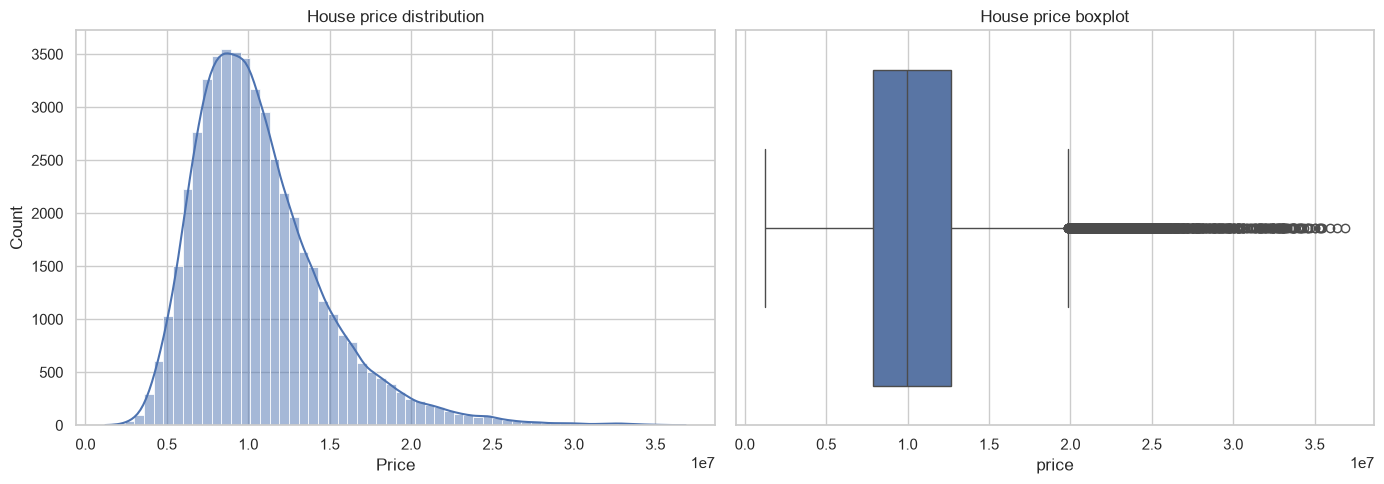

In [9]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df_model[TARGET], bins=60, kde=True, ax=axes[0])
axes[0].set_title("House price distribution")
axes[0].set_xlabel("Price")
sns.boxplot(x=df_model[TARGET], ax=axes[1])
axes[1].set_title("House price boxplot")
plt.tight_layout()
plt.show()

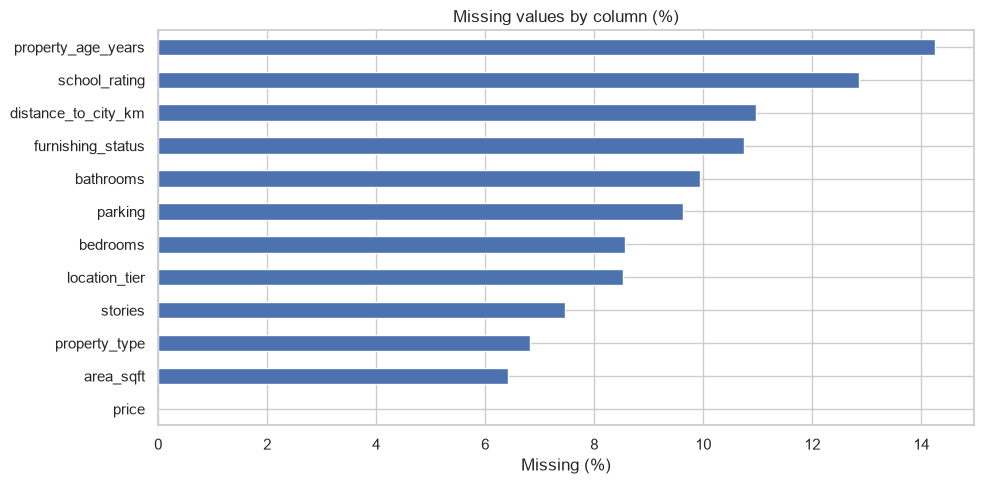

In [10]:
# Missingness after cleaning
missing_pct = (df_model.isna().mean() * 100).sort_values()
plt.figure(figsize=(10, 5))
missing_pct.plot(kind="barh")
plt.title("Missing values by column (%)")
plt.xlabel("Missing (%)")
plt.tight_layout()
plt.show()

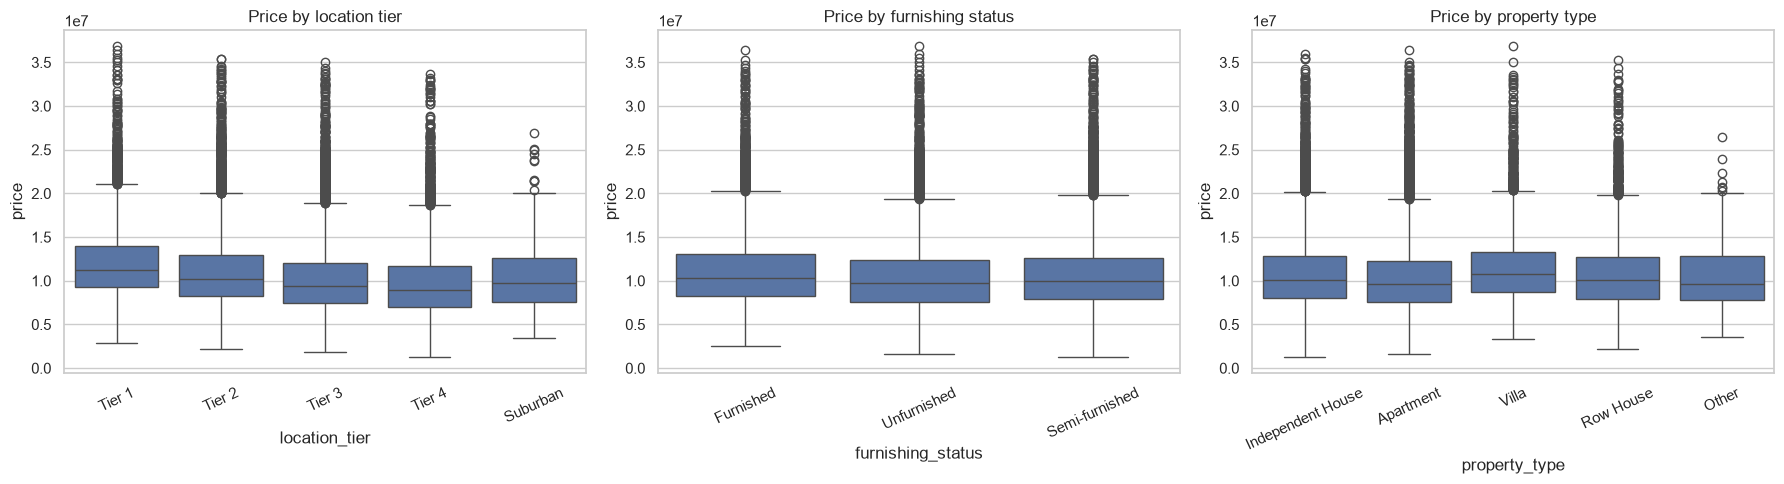

In [11]:
# Price by category
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, column in zip(axes, CATEGORICAL_COLUMNS):
    sns.boxplot(data=df_model, x=column, y=TARGET, ax=axis)
    axis.set_title(f"Price by {column.replace('_', ' ')}")
    axis.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

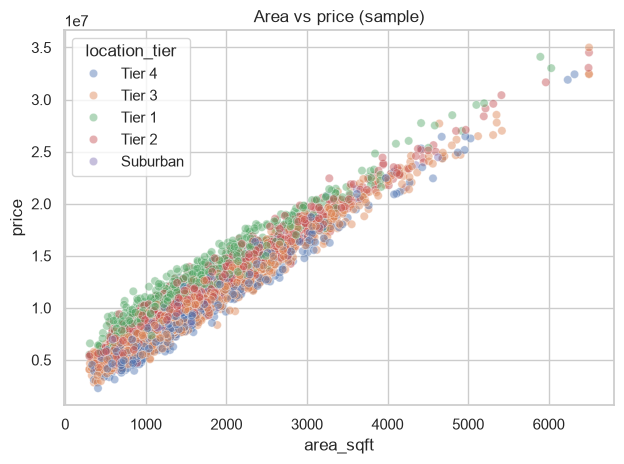

In [12]:
# Area vs price (sampled for readability)
eda_sample = df_model.sample(min(6000, len(df_model)), random_state=RANDOM_STATE)
sns.scatterplot(
    data=eda_sample, x="area_sqft", y=TARGET,
    hue="location_tier", alpha=0.45
)
plt.title("Area vs price (sample)")
plt.tight_layout()
plt.show()

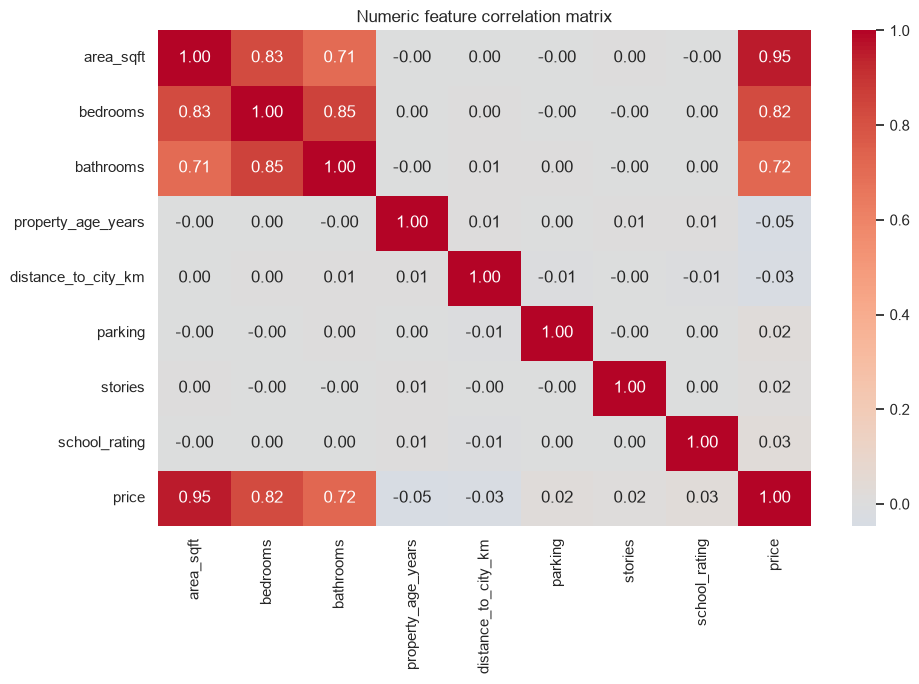

In [13]:
# Numeric correlations
correlation = df_model.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", center=0, cmap="coolwarm")
plt.title("Numeric feature correlation matrix")
plt.tight_layout()
plt.show()

Feature engineering and target separation

In [14]:
def add_features(frame):
    """Create derived features without using the target column."""
    engineered = frame.copy()
    bedrooms_safe = engineered["bedrooms"].replace(0, np.nan)
    engineered["area_per_bedroom"] = engineered["area_sqft"] / bedrooms_safe
    engineered["bathrooms_per_bedroom"] = engineered["bathrooms"] / bedrooms_safe
    return engineered

X = df_model.drop(columns=[TARGET]).copy()
y = df_model[TARGET].copy()
X = add_features(X)

print("Feature matrix:", X.shape)
print("Target vector:", y.shape)
display(y.describe().to_frame("Target_Summary"))

Feature matrix: (49600, 13)
Target vector: (49600,)


,Target_Summary
count,4.960000e+04
mean,1.069860e+07
std,4.086896e+06
min,1.228973e+06
25%,7.862626e+06
50%,9.966366e+06
75%,1.266577e+07
max,3.686682e+07


Train-test split

In [15]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=RANDOM_STATE,
)

print(f"Training rows: {len(X_train):,}")
print(f"Testing rows:  {len(X_test):,}")
print("Test data will be reserved for final evaluation.")

Training rows: 39,680
Testing rows:  9,920
Test data will be reserved for final evaluation.


preprocessing pipeline

In [16]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_pipeline, numeric_features),
        ("categorical", categorical_pipeline, categorical_features),
    ],
    remainder="drop",
)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Preprocessing is fitted within each pipeline/model training fold.")

Numeric features: ['area_sqft', 'bedrooms', 'bathrooms', 'property_age_years', 'distance_to_city_km', 'parking', 'stories', 'school_rating', 'area_per_bedroom', 'bathrooms_per_bedroom']
Categorical features: ['location_tier', 'furnishing_status', 'property_type']
Preprocessing is fitted within each pipeline/model training fold.


Evaluation helper and baseline model

In [17]:
def regression_metrics(y_true, predictions):
    """Return commonly used regression metrics in one place."""
    return {
        "MAE": mean_absolute_error(y_true, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_true, predictions)),
        "R2": r2_score(y_true, predictions),
    }

In [18]:
baseline_model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", DummyRegressor(strategy="median")),
])
baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)
baseline_metrics = regression_metrics(y_test, baseline_predictions)

display(pd.DataFrame([baseline_metrics], index=["Dummy Median Baseline"]).style.format("{:,.4f}"))

,MAE,RMSE,R2
Dummy Median Baseline,"3,046,050.0336","4,185,576.5165",-0.0321


Train and compare candidate models

In [19]:
candidate_models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=10.0),
    "Random Forest": RandomForestRegressor(
        n_estimators=120,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "Extra Trees": ExtraTreesRegressor(
        n_estimators=120,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=RANDOM_STATE,
    ),
    "Hist Gradient Boosting": HistGradientBoostingRegressor(
        max_iter=140,
        learning_rate=0.08,
        l2_regularization=1.0,
        random_state=RANDOM_STATE,
    ),
}

In [22]:
fitted_models = {}
comparison_rows = []

for model_name, estimator in candidate_models.items():
    print(f"Training: {model_name}")
    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("model", estimator),
    ])
    pipeline.fit(X_train, y_train)
    predictions = pipeline.predict(X_test)
    fitted_models[model_name] = pipeline
    comparison_rows.append({
        "Model": model_name,
        **regression_metrics(y_test, predictions),
    })


Training: Linear Regression
Training: Ridge Regression
Training: Random Forest
Training: Extra Trees
Training: Hist Gradient Boosting


model_comparison = (
    pd.DataFrame(comparison_rows)
    .sort_values("RMSE")
    .reset_index(drop=True)
)
display(model_comparison.style.format({
    "MAE": "{:,.2f}",
    "RMSE": "{:,.2f}",
    "R2": "{:.4f}",
}))

Cross-validation of leading candidate models

In [23]:
top_model_names = model_comparison["Model"].head(3).tolist()
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

cv_rows = []
for model_name in top_model_names:
    print(f"Cross-validating: {model_name}")
    scores = cross_validate(
        fitted_models[model_name],
        X_train,
        y_train,
        cv=cv,
        scoring={
            "mae": "neg_mean_absolute_error",
            "rmse": "neg_root_mean_squared_error",
            "r2": "r2",
        },
        n_jobs=1,
        return_train_score=False,
    )
    cv_rows.append({
        "Model": model_name,
        "Mean_CV_MAE": -scores["test_mae"].mean(),
        "Mean_CV_RMSE": -scores["test_rmse"].mean(),
        "Mean_CV_R2": scores["test_r2"].mean(),
        "Std_CV_R2": scores["test_r2"].std(),
    })


Cross-validating: Hist Gradient Boosting
Cross-validating: Random Forest
Cross-validating: Extra Trees


In [24]:
cv_results = pd.DataFrame(cv_rows).sort_values("Mean_CV_RMSE").reset_index(drop=True)
display(cv_results.style.format({
    "Mean_CV_MAE": "{:,.2f}",
    "Mean_CV_RMSE": "{:,.2f}",
    "Mean_CV_R2": "{:.4f}",
    "Std_CV_R2": "{:.4f}",
}))

,Model,Mean_CV_MAE,Mean_CV_RMSE,Mean_CV_R2,Std_CV_R2
0,Hist Gradient Boosting,"735,451.14","1,001,012.56",0.9396,0.0032
1,Random Forest,"770,841.52","1,038,072.83",0.9351,0.0027
2,Extra Trees,"780,406.22","1,057,700.73",0.9326,0.0032


Hyperparameter tuning — Hist Gradient Boosting

In [25]:
tuning_pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("model", HistGradientBoostingRegressor(random_state=RANDOM_STATE)),
])

parameter_distributions = {
    "model__learning_rate": uniform(0.03, 0.17),
    "model__max_iter": randint(100, 301),
    "model__max_leaf_nodes": randint(15, 41),
    "model__min_samples_leaf": randint(10, 41),
    "model__l2_regularization": uniform(0.0, 2.0),
}


In [26]:
search = RandomizedSearchCV(
    estimator=tuning_pipeline,
    param_distributions=parameter_distributions,
    n_iter=10,
    scoring="neg_root_mean_squared_error",
    cv=3,
    random_state=RANDOM_STATE,
    n_jobs=1,
    verbose=1,
    refit=True,
)

search.fit(X_train, y_train)
print("Best parameters:")
display(search.best_params_)
print(f"Best cross-validation RMSE: {-search.best_score_:,.2f}")

final_model = search.best_estimator_
final_model_name = "Tuned Hist Gradient Boosting"

Fitting 3 folds for each of 10 candidates, totalling 30 fits
Best parameters:


{'model__l2_regularization': np.float64(0.6674172222780437),
 'model__learning_rate': np.float64(0.05428735904672993),
 'model__max_iter': 230,
 'model__max_leaf_nodes': 36,
 'model__min_samples_leaf': 30}

Best cross-validation RMSE: 1,006,571.04


test set

In [28]:
test_predictions = final_model.predict(X_test)
final_metrics = regression_metrics(y_test, test_predictions)

final_results = pd.DataFrame([final_metrics], index=[final_model_name])
display(final_results.style.format({
    "MAE": "{:,.2f}",
    "RMSE": "{:,.2f}",
    "R2": "{:.4f}",
}))

print(f"Baseline MAE: {baseline_metrics['MAE']:,.2f}")
print(f"Final MAE:    {final_metrics['MAE']:,.2f}")
print(f"Baseline RMSE: {baseline_metrics['RMSE']:,.2f}")
print(f"Final RMSE:    {final_metrics['RMSE']:,.2f}")

,MAE,RMSE,R2
Tuned Hist Gradient Boosting,"725,040.78","985,108.13",0.9428


Baseline MAE: 3,046,050.03
Final MAE:    725,040.78
Baseline RMSE: 4,185,576.52
Final RMSE:    985,108.13


Prediction diagnostics and residual analysis

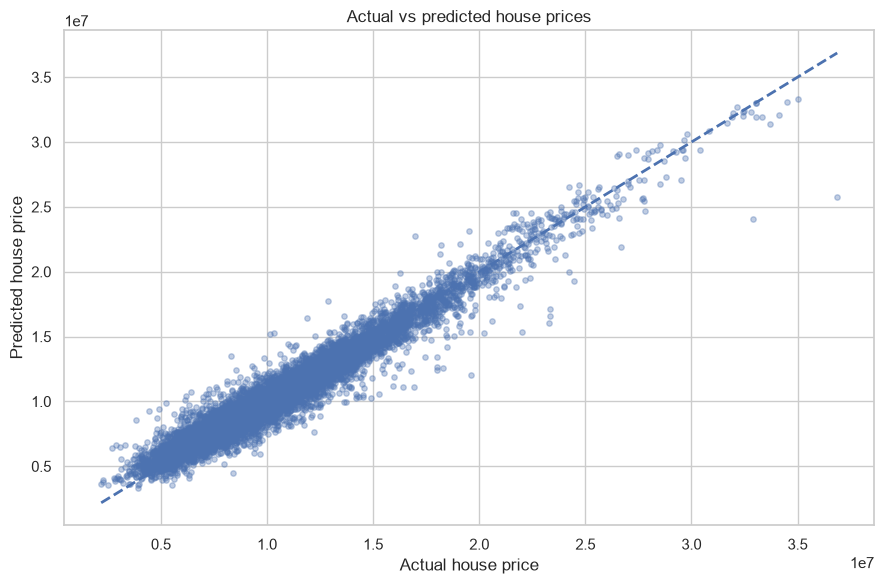

In [29]:
# Actual vs predicted
plt.figure(figsize=(9, 6))
plt.scatter(y_test, test_predictions, alpha=0.35, s=15)
lower = min(y_test.min(), test_predictions.min())
upper = max(y_test.max(), test_predictions.max())
plt.plot([lower, upper], [lower, upper], linestyle="--", linewidth=2)
plt.xlabel("Actual house price")
plt.ylabel("Predicted house price")
plt.title("Actual vs predicted house prices")
plt.tight_layout()
plt.show()

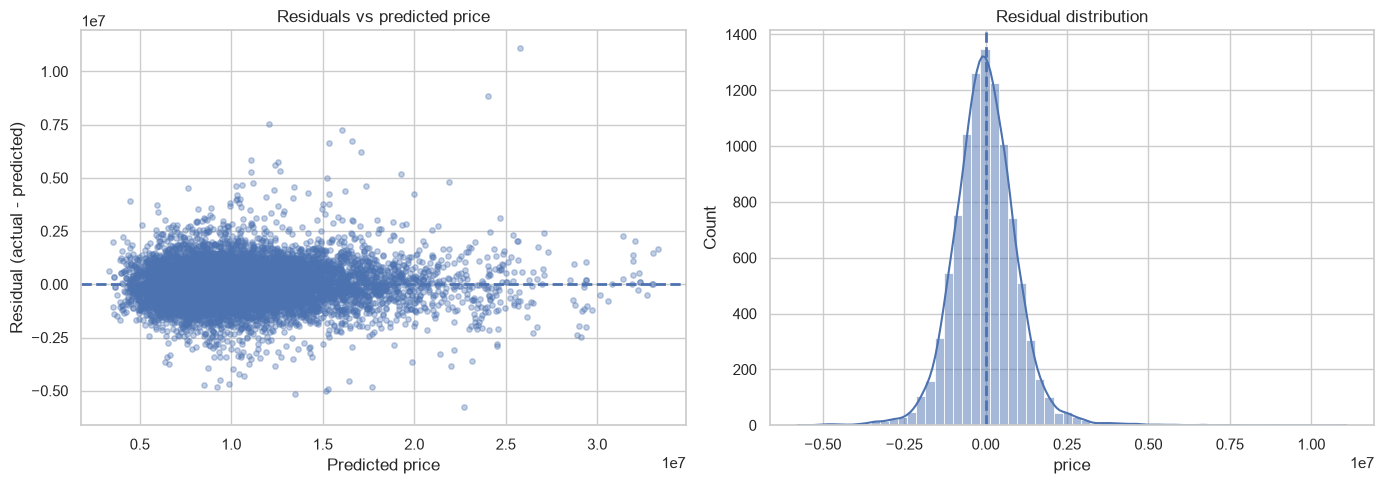

Mean residual: -11,095.41
Median absolute error: 570,546.44


,Residual_Summary
count,9.920000e+03
mean,-1.109541e+04
std,9.850953e+05
min,-5.780931e+06
25%,-5.932336e+05
50%,-2.926867e+04
75%,5.496269e+05
max,1.108442e+07


In [30]:
residuals = y_test - test_predictions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].scatter(test_predictions, residuals, alpha=0.35, s=15)
axes[0].axhline(0, linestyle="--", linewidth=2)
axes[0].set_xlabel("Predicted price")
axes[0].set_ylabel("Residual (actual - predicted)")
axes[0].set_title("Residuals vs predicted price")

sns.histplot(residuals, bins=60, kde=True, ax=axes[1])
axes[1].axvline(0, linestyle="--", linewidth=2)
axes[1].set_title("Residual distribution")
plt.tight_layout()
plt.show()

print(f"Mean residual: {residuals.mean():,.2f}")
print(f"Median absolute error: {np.median(np.abs(residuals)):,.2f}")
display(residuals.describe().to_frame("Residual_Summary"))

Inspect the largest prediction errors

In [31]:
error_analysis = X_test.copy()
error_analysis["Actual_Price"] = y_test
error_analysis["Predicted_Price"] = test_predictions
error_analysis["Residual"] = y_test - test_predictions
error_analysis["Absolute_Error"] = error_analysis["Residual"].abs()
error_analysis["Absolute_Percentage_Error"] = (
    error_analysis["Absolute_Error"] / error_analysis["Actual_Price"] * 100
)

In [32]:
largest_errors = error_analysis.nlargest(15, "Absolute_Error")
display(largest_errors.style.format({
    "Actual_Price": "{:,.0f}",
    "Predicted_Price": "{:,.0f}",
    "Residual": "{:,.0f}",
    "Absolute_Error": "{:,.0f}",
    "Absolute_Percentage_Error": "{:.2f}%",
}))

,area_sqft,bedrooms,bathrooms,property_age_years,distance_to_city_km,parking,stories,location_tier,furnishing_status,property_type,school_rating,area_per_bedroom,bathrooms_per_bedroom,Actual_Price,Predicted_Price,Residual,Absolute_Error,Absolute_Percentage_Error
43332,nan,8.000000,5.000000,7.400000,2.460000,1.000000,3.000000,Tier 1,Unfurnished,Villa,8.500000,nan,0.625000,"36,866,817","25,782,395","11,084,422","11,084,422",30.07%
32852,nan,8.000000,6.000000,39.300000,nan,2.000000,2.000000,Tier 2,Semi-furnished,Apartment,6.900000,nan,0.750000,"32,883,389","24,056,872","8,826,517","8,826,517",26.84%
23001,nan,nan,3.000000,nan,7.380000,2.000000,3.000000,Tier 2,Furnished,Apartment,8.300000,nan,nan,"19,623,597","12,069,990","7,553,607","7,553,607",38.49%
9084,nan,nan,5.000000,nan,3.090000,2.000000,1.000000,nan,Semi-furnished,Apartment,7.500000,nan,nan,"23,285,343","16,044,028","7,241,315","7,241,315",31.10%
20672,nan,6.000000,4.000000,31.300000,4.650000,2.000000,2.000000,nan,Semi-furnished,Apartment,7.300000,nan,0.666667,"23,329,689","16,600,331","6,729,358","6,729,358",28.84%
41875,nan,nan,5.000000,nan,nan,2.000000,nan,Tier 3,Semi-furnished,Apartment,3.700000,nan,nan,"22,024,523","15,366,737","6,657,786","6,657,786",30.23%
3441,nan,6.000000,4.000000,11.700000,2.310000,2.000000,2.000000,Tier 3,Unfurnished,Independent House,nan,nan,0.666667,"23,318,774","17,095,152","6,223,622","6,223,622",26.69%
32895,nan,3.000000,nan,21.200000,1.890000,1.000000,2.000000,Tier 1,Semi-furnished,Apartment,6.800000,nan,nan,"16,942,611","11,091,663","5,850,948","5,850,948",34.53%
24196,nan,7.000000,4.000000,19.300000,16.960000,1.000000,3.000000,Tier 1,Semi-furnished,Independent House,5.500000,nan,0.571429,"16,957,553","22,738,484","-5,780,931","5,780,931",34.09%
24666,nan,4.000000,3.000000,8.500000,10.370000,1.000000,3.000000,Tier 3,Furnished,Independent House,nan,nan,0.750000,"18,301,556","12,553,469","5,748,087","5,748,087",31.41%


In [33]:
tier_error_summary = error_analysis.groupby("location_tier", dropna=False).agg(
    Rows=("Actual_Price", "size"),
    MAE=("Absolute_Error", "mean"),
    Median_Absolute_Error=("Absolute_Error", "median"),
    Mean_Absolute_Percentage_Error=("Absolute_Percentage_Error", "mean"),
).sort_values("MAE")
display(tier_error_summary.style.format({
    "MAE": "{:,.2f}",
    "Median_Absolute_Error": "{:,.2f}",
    "Mean_Absolute_Percentage_Error": "{:.2f}%",
}))

,Rows,MAE,Median_Absolute_Error,Mean_Absolute_Percentage_Error
location_tier,,,,
Tier 2,2756,"684,384.17","545,747.23",6.94%
Tier 4,1451,"696,108.38","536,455.94",8.47%
Tier 3,3255,"698,158.24","555,902.93",7.93%
Tier 1,1550,"757,698.41","580,703.16",6.76%
Suburban,62,"872,677.42","804,353.70",9.29%
nan,846,"939,887.63","759,575.69",9.74%


Permutation feature importance

In [34]:
importance_sample_size = min(2500, len(X_test))
X_importance = X_test.sample(importance_sample_size, random_state=RANDOM_STATE)
y_importance = y_test.loc[X_importance.index]

importance_result = permutation_importance(
    final_model,
    X_importance,
    y_importance,
    scoring="neg_root_mean_squared_error",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=1,
)

importance_df = pd.DataFrame({
    "Feature": X_importance.columns,
    "Importance_Mean": importance_result.importances_mean,
    "Importance_Std": importance_result.importances_std,
}).sort_values("Importance_Mean", ascending=False).reset_index(drop=True)

display(importance_df.style.format({
    "Importance_Mean": "{:,.2f}",
    "Importance_Std": "{:,.2f}",
}))

,Feature,Importance_Mean,Importance_Std
0,area_sqft,"3,893,086.37","72,125.66"
1,bedrooms,"798,676.49","16,036.55"
2,location_tier,"423,194.44","2,463.81"
3,property_type,"108,779.38","5,032.05"
4,bathrooms,"97,110.73","12,549.86"
5,area_per_bedroom,"75,582.00","1,600.84"
6,furnishing_status,"50,880.12","2,219.00"
7,property_age_years,"39,047.03","8,290.86"
8,distance_to_city_km,"18,148.83","6,093.85"
9,school_rating,"6,428.69","2,031.98"


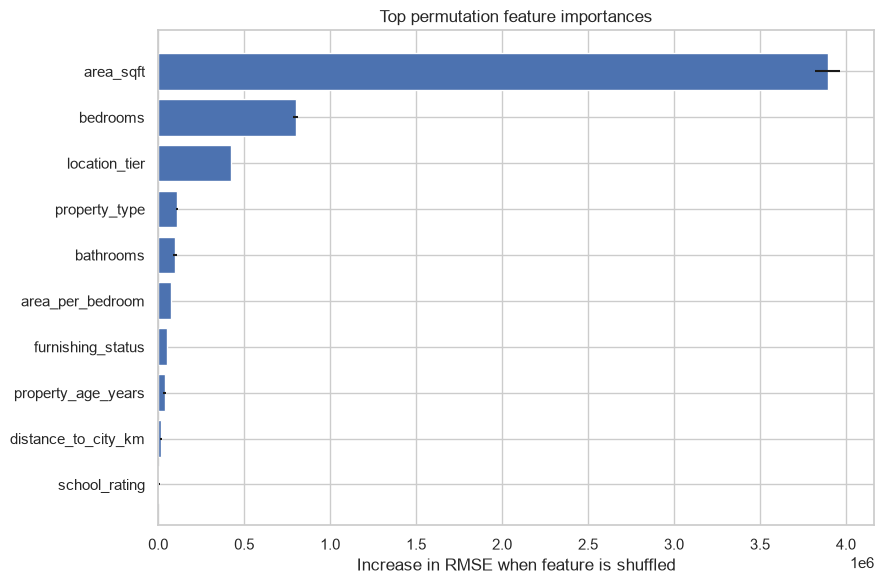

In [35]:
top_features = importance_df.head(10).sort_values("Importance_Mean")
plt.figure(figsize=(9, 6))
plt.barh(
    top_features["Feature"],
    top_features["Importance_Mean"],
    xerr=top_features["Importance_Std"],
)
plt.xlabel("Increase in RMSE when feature is shuffled")
plt.title("Top permutation feature importances")
plt.tight_layout()
plt.show()

Save and reload the final model

In [36]:
MODEL_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(final_model, MODEL_PATH)

print("Model saved to:", MODEL_PATH.resolve())
print(f"Model size: {MODEL_PATH.stat().st_size / 1024:.2f} KB")

loaded_model = joblib.load(MODEL_PATH)
print("Saved model reloaded successfully.")

Model saved to: C:\Users\anami\HPP\models\house_price_model.joblib
Model size: 841.75 KB
Saved model reloaded successfully.


verification

In [37]:
new_property = pd.DataFrame([{
    "area_sqft": 1500,
    "bedrooms": 3,
    "bathrooms": 2,
    "property_age_years": 8,
    "distance_to_city_km": 5.5,
    "parking": 1,
    "stories": 2,
    "location_tier": "Tier 2",
    "furnishing_status": "Semi-furnished",
    "property_type": "Apartment",
    "school_rating": 7.2,
}])

new_property = add_features(new_property)
predicted_price = loaded_model.predict(new_property)[0]
print(f"Predicted synthetic price: ₹{predicted_price:,.2f}")

original_prediction = final_model.predict(new_property)[0]
reloaded_prediction = loaded_model.predict(new_property)[0]

if np.isclose(original_prediction, reloaded_prediction):
    print("PASS: Original and reloaded models return the same prediction.")
else:
    raise AssertionError("Saved-model prediction differs from the original model.")

Predicted synthetic price: ₹10,571,683.14
PASS: Original and reloaded models return the same prediction.


In [38]:
MODEL_PATH = Path("house_price_enterprise_pipeline.joblib")
joblib.dump(final_model, MODEL_PATH)
print("Saved model:", MODEL_PATH.resolve())

new_property = pd.DataFrame([{
    "area_sqft": 1500,
    "bedrooms": 3,
    "bathrooms": 2,
    "property_age_years": 8,
    "distance_to_city_km": 5.5,
    "parking": 1,
    "stories": 2,
    "location_tier": "Tier 2",
    "furnishing_status": "Semi-furnished",
    "property_type": "Apartment",
    "school_rating": 7.2
}])
new_property = add_features(new_property)
loaded_pipeline = joblib.load(MODEL_PATH)
predicted_price = loaded_pipeline.predict(new_property)[0]
print(f"Predicted synthetic price: {predicted_price:,.0f}")

Saved model: C:\Users\anami\HPP\house_price_enterprise_pipeline.joblib
Predicted synthetic price: 10,571,683
